<a href="https://colab.research.google.com/github/Basma328/Beginning_Bioinformatics/blob/main/Tuesday%20work%20visualization%20part%20of%20the%20project%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Install UMAP and import the tools

In [12]:
%pip -q install umap-learn

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from google.colab import files
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

2. Read the cleaned data and training IDs
This cell finds the cleaned dataset as either .csv or .csv.gz, reads it, and reads training_ids.csv.

In [13]:
DATA_DIR = Path("/content")

cleaned_options = sorted(DATA_DIR.glob("camptothecin_cleaned_full.csv*"))
training_file = DATA_DIR / "training_ids.csv"

if not cleaned_options:
    raise FileNotFoundError(
        "Could not find camptothecin_cleaned_full.csv or .csv.gz in /content."
    )

if not training_file.exists():
    raise FileNotFoundError("Could not find training_ids.csv in /content.")

# Prefer the compressed file if both versions are present
cleaned_file = next(
    (path for path in cleaned_options if path.name.lower().endswith(".csv.gz")),
    cleaned_options[0]
)

data = pd.read_csv(cleaned_file, compression="infer")
training_ids_df = pd.read_csv(training_file)

# Clean column names
data.columns = (
    data.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)
training_ids_df.columns = (
    training_ids_df.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

print("Cleaned dataset:", cleaned_file.name)
print("Training IDs file:", training_file.name)
print("Dataset dimensions:", data.shape)

Cleaned dataset: camptothecin_cleaned_full.csv
Training IDs file: training_ids.csv
Dataset dimensions: (579, 54140)


3. Select the 463 training cell lines
This cell checks IDs and keeps only the cell lines listed in training_ids.csv. The order follows that file.

In [14]:
if "sampleId" not in data.columns:
    raise ValueError("The cleaned dataset needs a 'sampleId' column.")

if "sampleId" not in training_ids_df.columns:
    raise ValueError("training_ids.csv needs a 'sampleId' column.")

if not {"cancer_type", "AUC"}.issubset(data.columns):
    raise ValueError("The cleaned dataset needs 'cancer_type' and 'AUC' columns.")

data["sampleId"] = data["sampleId"].astype("string").str.strip()
training_ids_df["sampleId"] = (
    training_ids_df["sampleId"].astype("string").str.strip()
)

if data["sampleId"].isna().any() or (data["sampleId"] == "").any():
    raise ValueError("Blank sample IDs found in the cleaned dataset.")

if training_ids_df["sampleId"].isna().any() or (
    training_ids_df["sampleId"] == ""
).any():
    raise ValueError("Blank sample IDs found in training_ids.csv.")

if data["sampleId"].duplicated().any():
    raise ValueError("Duplicate sample IDs found in the cleaned dataset.")

if training_ids_df["sampleId"].duplicated().any():
    raise ValueError("Duplicate sample IDs found in training_ids.csv.")

training_ids = training_ids_df["sampleId"].astype(str).tolist()

if len(training_ids) != 463:
    raise ValueError(f"Expected 463 training IDs; found {len(training_ids)}.")

data["sampleId"] = data["sampleId"].astype(str)
data = data.set_index("sampleId", drop=False)

missing_ids = [sid for sid in training_ids if sid not in data.index]
if missing_ids:
    raise ValueError(
        f"{len(missing_ids)} training IDs were not found. "
        f"Examples: {missing_ids[:10]}"
    )

train = data.loc[training_ids].copy()

print("Matched training cell lines:", len(train))
print("Cancer types represented:", train["cancer_type"].nunique())

Matched training cell lines: 463
Cancer types represented: 35


4. Prepare the gene-expression inputs
Only gene-expression columns go into PCA and UMAP. The code keeps cancer type and AUC separate for coloring the plots. It transforms RPKM with log2(RPKM + 1), removes incomplete and constant genes, then standardizes each gene.

In [15]:
# Keep labels separate; they will only be used to color the plots
plot_metadata = train[["sampleId", "cancer_type", "AUC"]].copy()
plot_metadata["cancer_type"] = plot_metadata["cancer_type"].astype(str)
plot_metadata["AUC"] = pd.to_numeric(plot_metadata["AUC"], errors="coerce")

if plot_metadata[["cancer_type", "AUC"]].isna().any().any():
    raise ValueError("Missing cancer type or invalid AUC in training data.")

# Exclude metadata columns from the analysis inputs
metadata_columns = {"sampleId", "cancer_type", "AUC"}
gene_columns = [col for col in train.columns if col not in metadata_columns]

if not gene_columns:
    raise ValueError("No gene-expression columns were found.")

# Convert expression values to numbers
X_rpkm = train[gene_columns].apply(pd.to_numeric, errors="coerce")
X_rpkm = X_rpkm.replace([np.inf, -np.inf], np.nan)

# Remove genes with missing or invalid values
invalid_gene_mask = X_rpkm.isna().any(axis=0)
invalid_gene_count = int(invalid_gene_mask.sum())
X_rpkm = X_rpkm.loc[:, ~invalid_gene_mask]

if X_rpkm.shape[1] == 0:
    raise ValueError("No complete numeric gene-expression columns remain.")

if (X_rpkm < 0).any().any():
    raise ValueError("Negative RPKM values found; log2(RPKM + 1) requires non-negative values.")

# Transform RPKM values
X_log = np.log2(X_rpkm + 1)

# Remove genes that do not vary across the training cell lines
constant_gene_mask = X_log.nunique(axis=0, dropna=False) <= 1
constant_gene_count = int(constant_gene_mask.sum())
X_log = X_log.loc[:, ~constant_gene_mask]

if X_log.shape[1] == 0:
    raise ValueError("No variable genes remain after filtering.")

# Standardize each gene across the 463 training cell lines
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Starting gene columns:", len(gene_columns))
print("Genes removed for missing/invalid values:", invalid_gene_count)
print("Constant genes removed:", constant_gene_count)
print("Genes retained:", X_log.shape[1])
print("Final expression matrix dimensions:", X_scaled.shape)

Starting gene columns: 54137
Genes removed for missing/invalid values: 0
Constant genes removed: 3653
Genes retained: 50484
Final expression matrix dimensions: (463, 50484)


5. Run PCA and create the scree plot
PCA uses the standardized expression matrix. PC1 and PC2 form the 2D map; the scree plot shows how much variation the leading components explain.

PC1 variance explained: 4.98%
PC2 variance explained: 3.36%
PC1 + PC2 variance explained: 8.34%


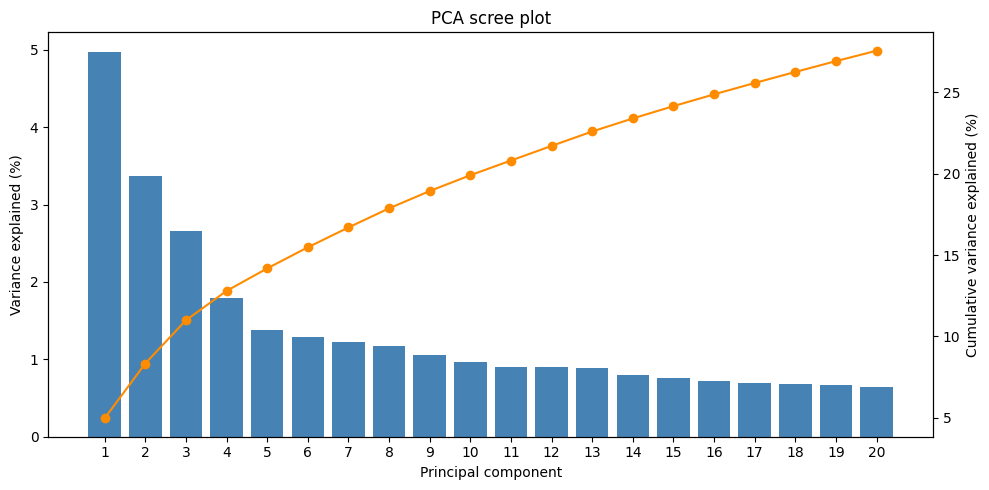

In [16]:
N_PCS = min(50, X_scaled.shape[0] - 1, X_scaled.shape[1])

pca = PCA(
    n_components=N_PCS,
    svd_solver="randomized",
    random_state=SEED
)

pca_scores = pca.fit_transform(X_scaled)
pca_coordinates = pca_scores[:, :2]
explained = pca.explained_variance_ratio_

print(f"PC1 variance explained: {explained[0] * 100:.2f}%")
print(f"PC2 variance explained: {explained[1] * 100:.2f}%")
print(f"PC1 + PC2 variance explained: {explained[:2].sum() * 100:.2f}%")

# Scree plot for up to the first 20 PCs
number_to_plot = min(20, N_PCS)
components = np.arange(1, number_to_plot + 1)
variance_percent = explained[:number_to_plot] * 100
cumulative_percent = np.cumsum(variance_percent)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(components, variance_percent, color="steelblue")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Variance explained (%)")
ax1.set_xticks(components)
ax1.set_title("PCA scree plot")

ax2 = ax1.twinx()
ax2.plot(components, cumulative_percent, color="darkorange", marker="o")
ax2.set_ylabel("Cumulative variance explained (%)")

plt.tight_layout()
plt.show()

Explain:Blue bars: how much of the expression variation each principal component explains individually.
Orange line: how much variation is explained cumulatively as more components are included.
Your PC1 explains 4.98% and PC2 explains 3.36%; together, they explain 8.34%.
This plot helps show how much information is compressed into the components. The components are summaries of many genes, not individual cell lines or genes. **bold text**

6. Plot PCA by cancer type and AUC
This function uses the same PCA coordinates for both plots. Cancer type is categorical; AUC uses a continuous color scale.

In [17]:
print(f"First {N_PCS} PCs explain {explained.sum() * 100:.2f}% of variance")

First 50 PCs explain 40.56% of variance


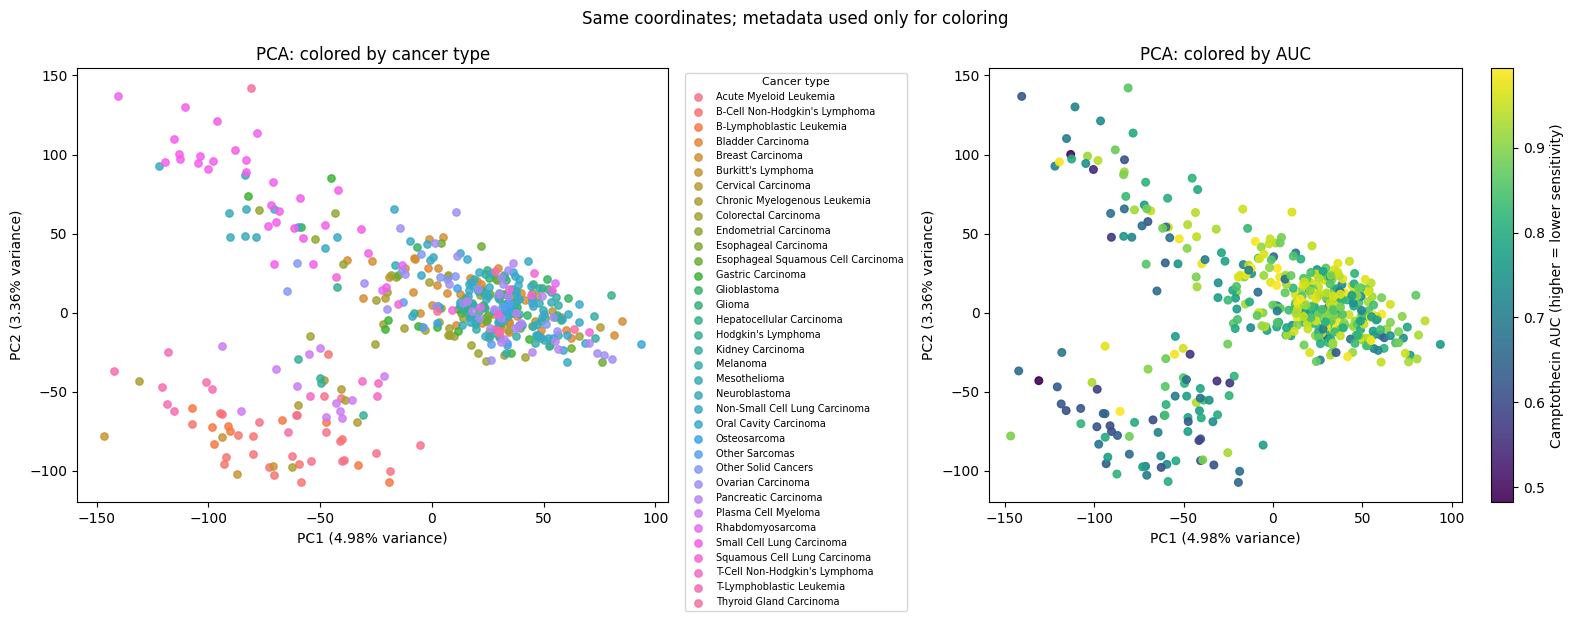

In [18]:
def plot_embedding(coords, axis_labels, method_name):
    cancer_types = plot_metadata["cancer_type"].to_numpy()
    auc_values = plot_metadata["AUC"].to_numpy(dtype=float)
    categories = sorted(pd.unique(cancer_types))
    colors = sns.color_palette("husl", n_colors=len(categories))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Same coordinates, colored by cancer type
    for cancer, color in zip(categories, colors):
        mask = cancer_types == cancer
        axes[0].scatter(
            coords[mask, 0],
            coords[mask, 1],
            color=color,
            label=cancer,
            s=28,
            alpha=0.82
        )

    axes[0].set_xlabel(axis_labels[0])
    axes[0].set_ylabel(axis_labels[1])
    axes[0].set_title(f"{method_name}: colored by cancer type")
    axes[0].legend(
        title="Cancer type",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=7,
        title_fontsize=8
    )

    # Same coordinates, colored by continuous AUC
    points = axes[1].scatter(
        coords[:, 0],
        coords[:, 1],
        c=auc_values,
        cmap="viridis",
        s=30,
        alpha=0.9
    )

    colorbar = fig.colorbar(points, ax=axes[1])
    colorbar.set_label("Camptothecin AUC (higher = lower sensitivity)")
    axes[1].set_xlabel(axis_labels[0])
    axes[1].set_ylabel(axis_labels[1])
    axes[1].set_title(f"{method_name}: colored by AUC")

    fig.suptitle("Same coordinates; metadata used only for coloring")
    plt.tight_layout()
    plt.show()


plot_embedding(
    pca_coordinates,
    (
        f"PC1 ({explained[0] * 100:.2f}% variance)",
        f"PC2 ({explained[1] * 100:.2f}% variance)"
    ),
    "PCA"
)

3D PCA

In [34]:
import plotly.express as px

# Check that metadata rows match the PCA results
if len(plot_metadata) != len(pca_scores):
    raise ValueError("Metadata rows and PCA scores do not match.")

# Create a table for plotting the first three components
pca_3d = plot_metadata.reset_index(drop=True).copy()
pca_3d["PC1"] = pca_scores[:, 0]
pca_3d["PC2"] = pca_scores[:, 1]
pca_3d["PC3"] = pca_scores[:, 2]

print(f"PC1 explains {explained[0] * 100:.2f}% of variance")
print(f"PC2 explains {explained[1] * 100:.2f}% of variance")
print(f"PC3 explains {explained[2] * 100:.2f}% of variance")
print(f"First 3 PCs together explain {explained[:3].sum() * 100:.2f}% of variance")

# Plot 1: color cell lines by cancer type
fig_cancer = px.scatter_3d(
    pca_3d,
    x="PC1",
    y="PC2",
    z="PC3",
    color="cancer_type",
    hover_name="sampleId",
    hover_data={"AUC": ":.3f"},
    title="3D PCA colored by cancer type"
)
fig_cancer.update_traces(marker={"size": 4, "opacity": 0.8})
fig_cancer.show()

# Plot 2: use the same coordinates, colored by AUC
fig_auc = px.scatter_3d(
    pca_3d,
    x="PC1",
    y="PC2",
    z="PC3",
    color="AUC",
    color_continuous_scale="Viridis",
    hover_name="sampleId",
    hover_data={"cancer_type": True, "AUC": ":.3f"},
    title="3D PCA colored by camptothecin AUC"
)
fig_auc.update_traces(marker={"size": 4, "opacity": 0.8})
fig_auc.show()

PC1 explains 4.98% of variance
PC2 explains 3.36% of variance
PC3 explains 2.65% of variance
First 3 PCs together explain 11.00% of variance


In [23]:
print(f"PC1 explains {explained[0] * 100:.2f}%")
print(f"PC2 explains {explained[1] * 100:.2f}%")
print(f"PC3 explains {explained[2] * 100:.2f}%")
print(f"First 3 PCs together explain {explained[:3].sum() * 100:.2f}%")

PC1 explains 4.98%
PC2 explains 3.36%
PC3 explains 2.65%
First 3 PCs together explain 11.00%


In [21]:
loadings = pd.DataFrame({
    "gene": X_log.columns,
    "PC1_loading": pca.components_[0],
    "PC2_loading": pca.components_[1]
})

print("Genes contributing most to PC1:")
display(loadings.reindex(
    loadings["PC1_loading"].abs().nlargest(10).index
))

print("Genes contributing most to PC2:")
display(loadings.reindex(
    loadings["PC2_loading"].abs().nlargest(10).index
))

Genes contributing most to PC1:


,gene,PC1_loading,PC2_loading
37204,TNFRSF12A,0.017258,0.004779
26319,MYOF,0.016671,0.003221
36073,ANXA2,0.016500,0.003140
23292,ANXA2P2,0.015855,0.002874
477,EPHA2,0.015772,0.005055
31285,CPSF6,-0.015644,-0.000309
3043,LMNA,0.015633,0.007181
45901,SDC4,0.015618,0.007599
29172,YAP1,0.015616,0.005108
16763,USP49,-0.015609,0.000335


Genes contributing most to PC2:


,gene,PC1_loading,PC2_loading
27816,MAPK8IP1,-0.001940,0.017983
27817,RP11-618K13.2,-0.001980,0.017406
41432,CCDC40,-0.003546,0.017395
309,KIF1B,-0.001006,0.017235
40896,MIR142,-0.011513,-0.016981
2262,CD53,-0.011085,-0.016869
1994,FNBP1L,0.003218,0.016829
19032,IKZF1,-0.012043,-0.016789
48598,WAS,-0.012083,-0.016768
7392,NCKAP1,0.010981,0.016762


In [20]:
print("Genes included in PC1:", pca.components_[0].size)
print("Genes included in PC2:", pca.components_[1].size)
print("Unique genes across PC1 and PC2:", len(X_log.columns))


Genes included in PC1: 50484
Genes included in PC2: 50484
Unique genes across PC1 and PC2: 50484


In [35]:
import plotly.express as px

# Keep the metadata in the same order as the PCA coordinates
plot_df = plot_metadata.reset_index(drop=True).copy()

if len(plot_df) != len(pca_coordinates):
    raise ValueError("The metadata rows and PCA coordinates do not match.")

plot_df["PC1"] = pca_coordinates[:, 0]
plot_df["PC2"] = pca_coordinates[:, 1]

fig = px.scatter(
    plot_df,
    x="PC1",
    y="PC2",
    color="AUC",
    color_continuous_scale="Viridis",
    hover_name="sampleId",
    hover_data={
        "cancer_type": True,
        "AUC": ":.3f",
        "PC1": False,
        "PC2": False
    },
    title="PCA: hover over a dot to identify the cell line"
)

fig.update_traces(marker={"size": 9, "opacity": 0.85})
fig.show()

Explain:two maps from the same PCA coordinates:
- Colored by cancer type: each dot is a cell line; colors identify cancer types. Groups of similar colors may suggest that some cell lines have similar expression profiles.
- Colored by AUC: the color scale shows camptothecin AUC. Higher AUC means lower camptothecin sensitivity.
The PC1 and PC2 axes are the two main expression patterns found by PCA. They do not represent cancer type or AUC; those values are used only to color the dots. **bold text**

7. Run UMAP and make its two plots
UMAP uses the first 50 PCA components to make the calculation more manageable. Its settings, including random_state=42, are printed so you can report them.

UMAP input: first 50 PCA components
UMAP settings:
n_components: 2
n_neighbors: 15
min_dist: 0.1
metric: euclidean
random_state: 42
transform_seed: 42
init: spectral
low_memory: True
n_jobs: 1


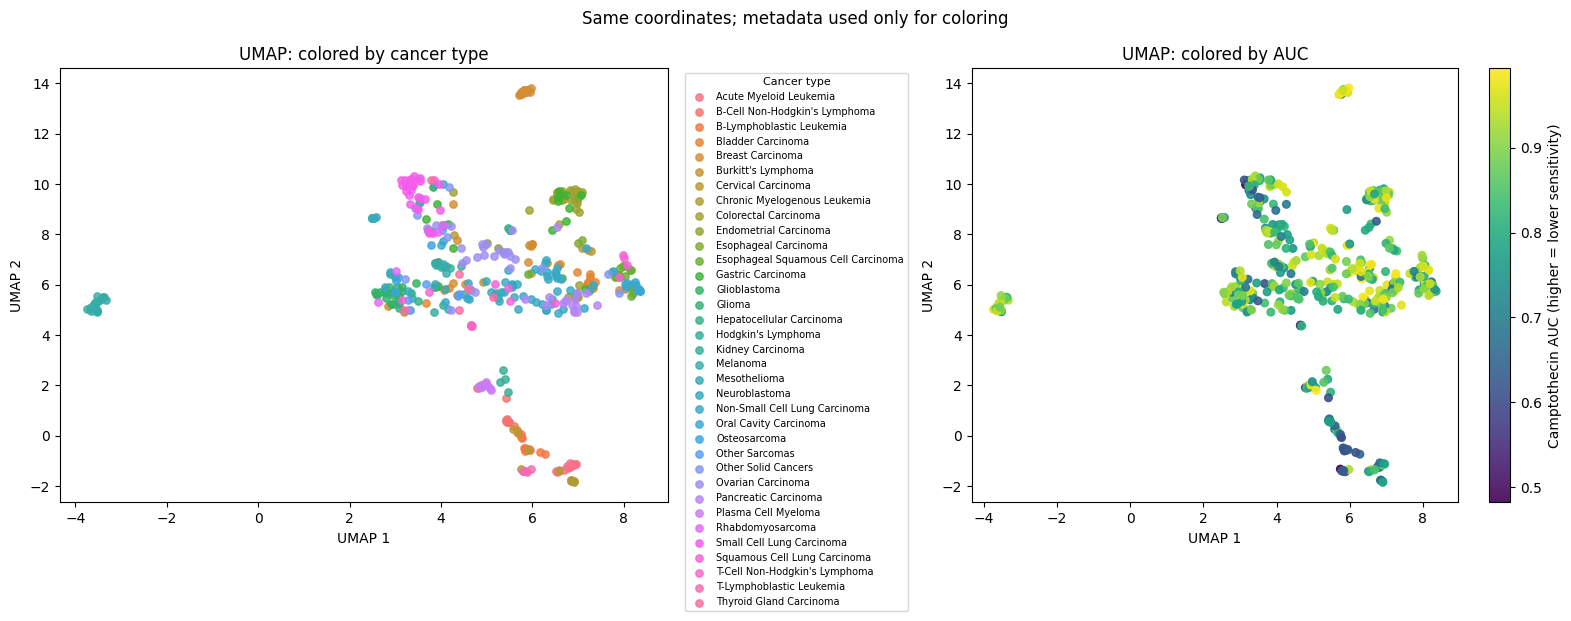

In [36]:
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 15,
    "min_dist": 0.1,
    "metric": "euclidean",
    "random_state": SEED,
    "transform_seed": SEED,
    "init": "spectral",
    "low_memory": True,
    "n_jobs": 1
}

umap_model = umap.UMAP(**UMAP_SETTINGS)
umap_coordinates = umap_model.fit_transform(pca_scores)

print("UMAP input: first", pca_scores.shape[1], "PCA components")
print("UMAP settings:")
for setting, value in UMAP_SETTINGS.items():
    print(f"{setting}: {value}")

plot_embedding(
    umap_coordinates,
    ("UMAP 1", "UMAP 2"),
    "UMAP"
)

Explain:These also use the same UMAP coordinates, colored once by cancer type and once by AUC.
- Nearby dots represent cell lines with similar expression profiles, according to UMAP.
- The cancer-type version shows whether nearby cell lines tend to share a cancer type.
- The AUC version shows whether nearby cell lines tend to have similar drug-response values.
UMAP 1 and UMAP 2 are map coordinates, not individual genes. UMAP emphasizes local neighborhoods, so interpret nearby groups more than the overall distance between far-apart groups. **bold text**

First 50 PCs explain: 40.85%
First 100 PCs explain: 54.76%


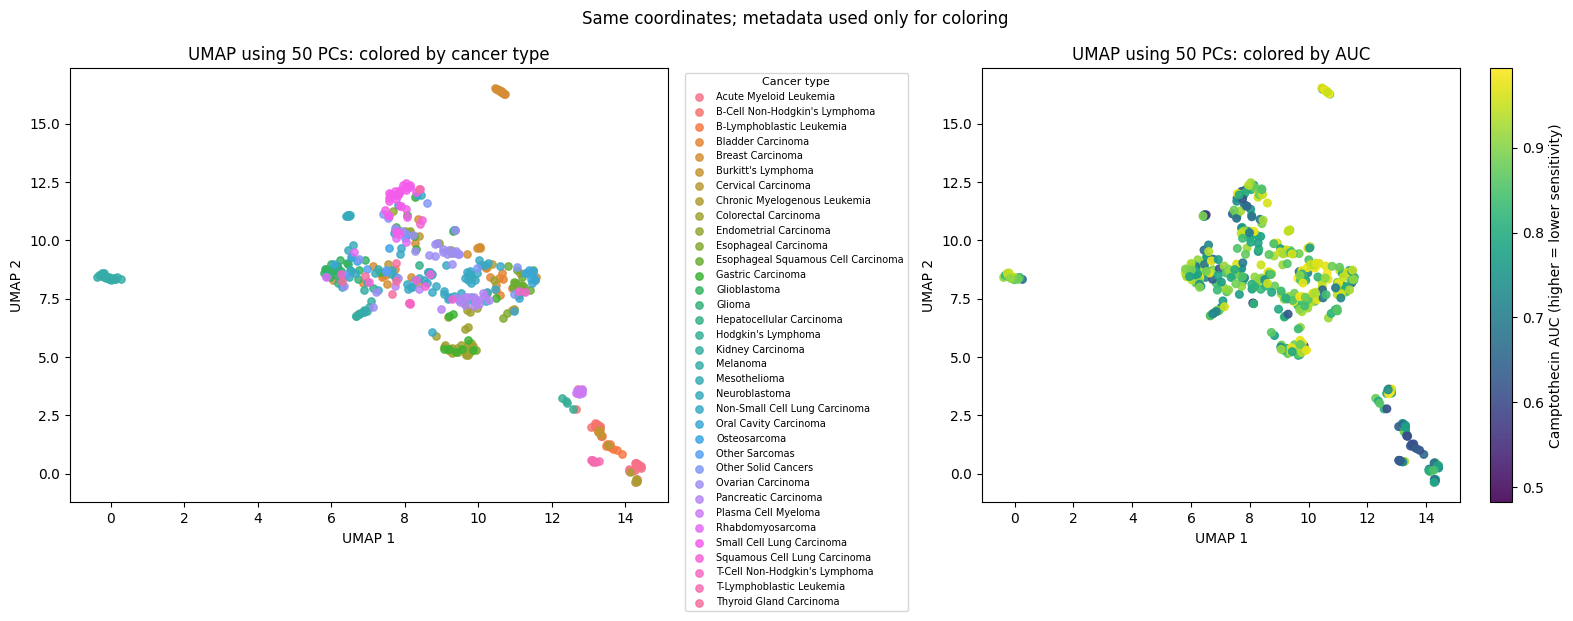

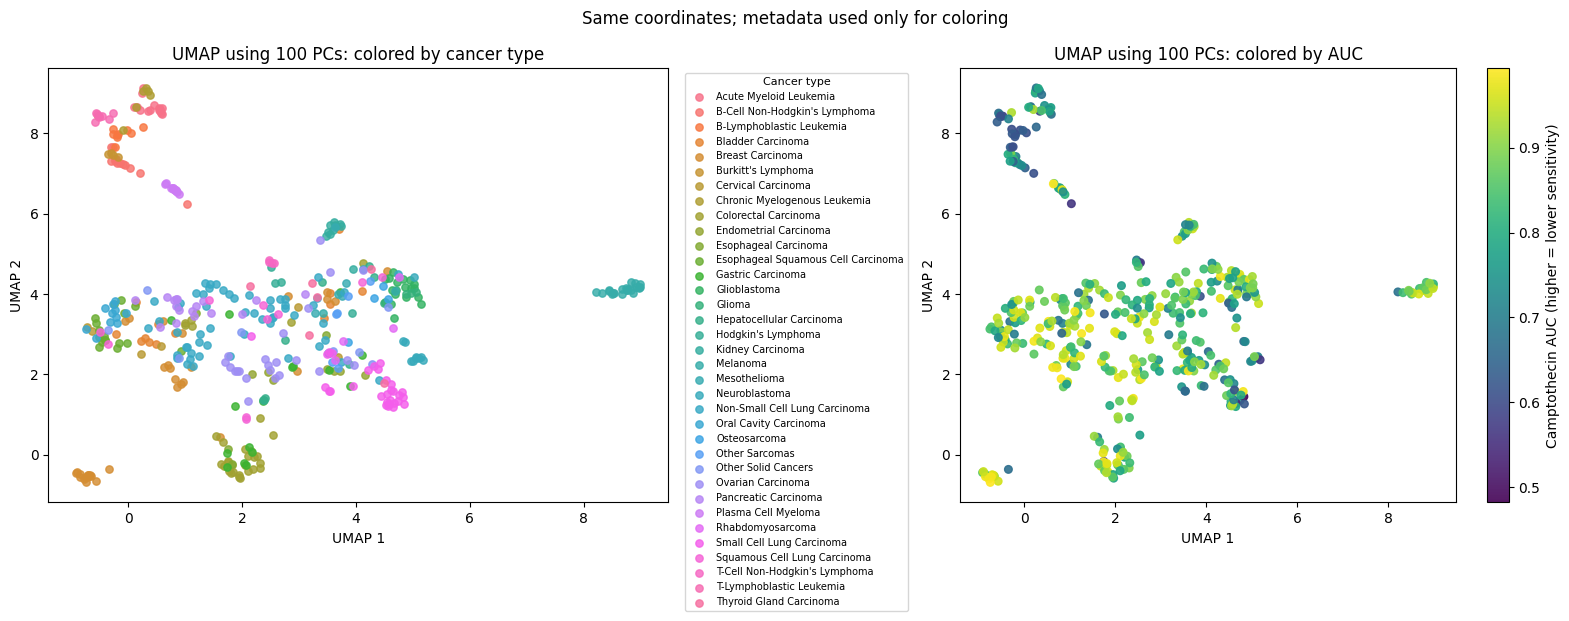

In [29]:
from sklearn.decomposition import PCA
import umap

SEED = 42

# Calculate 100 PCs from the standardized gene-expression data
N_PCS_COMPARE = min(100, X_scaled.shape[0] - 1, X_scaled.shape[1])

pca_compare = PCA(
    n_components=N_PCS_COMPARE,
    svd_solver="randomized",
    random_state=SEED
)

scores_100 = pca_compare.fit_transform(X_scaled)

# Compare how much variation is represented
print(f"First 50 PCs explain: "
      f"{pca_compare.explained_variance_ratio_[:50].sum() * 100:.2f}%")
print(f"First 100 PCs explain: "
      f"{pca_compare.explained_variance_ratio_[:100].sum() * 100:.2f}%")

# Keep the same UMAP settings for both comparisons
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 15,
    "min_dist": 0.1,
    "metric": "euclidean",
    "random_state": SEED,
    "transform_seed": SEED,
    "init": "spectral",
    "low_memory": True,
    "n_jobs": 1
}

# UMAP using the first 50 PCs
umap_50 = umap.UMAP(**UMAP_SETTINGS)
coordinates_50 = umap_50.fit_transform(scores_100[:, :50])

# UMAP using the first 100 PCs
umap_100 = umap.UMAP(**UMAP_SETTINGS)
coordinates_100 = umap_100.fit_transform(scores_100[:, :100])

# Each figure shows the embedding colored by cancer type and by AUC
plot_embedding(
    coordinates_50,
    ("UMAP 1", "UMAP 2"),
    "UMAP using 50 PCs"
)

plot_embedding(
    coordinates_100,
    ("UMAP 1", "UMAP 2"),
    "UMAP using 100 PCs"
)

In [37]:
from sklearn.decomposition import PCA
import umap
import plotly.express as px

SEED = 42

# Check that each expression row has matching metadata
plot_data = plot_metadata.reset_index(drop=True).copy()
if len(plot_data) != X_scaled.shape[0]:
    raise ValueError("The metadata rows and expression rows do not match.")

# Calculate 100 PCs from standardized gene-expression data
N_PCS_COMPARE = min(100, X_scaled.shape[0] - 1, X_scaled.shape[1])

pca_compare = PCA(
    n_components=N_PCS_COMPARE,
    svd_solver="randomized",
    random_state=SEED
)

scores_100 = pca_compare.fit_transform(X_scaled)

print(
    "First 50 PCs explain: "
    f"{pca_compare.explained_variance_ratio_[:50].sum() * 100:.2f}%"
)
print(
    f"First {N_PCS_COMPARE} PCs explain: "
    f"{pca_compare.explained_variance_ratio_[:N_PCS_COMPARE].sum() * 100:.2f}%"
)

# Keep the same UMAP settings for both comparisons
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 15,
    "min_dist": 0.1,
    "metric": "euclidean",
    "random_state": SEED,
    "transform_seed": SEED,
    "init": "spectral",
    "low_memory": True,
    "n_jobs": 1
}

# Run UMAP using the first 50 PCs
umap_50 = umap.UMAP(**UMAP_SETTINGS)
coordinates_50 = umap_50.fit_transform(scores_100[:, :50])

# Run UMAP using the first 100 PCs
umap_100 = umap.UMAP(**UMAP_SETTINGS)
coordinates_100 = umap_100.fit_transform(scores_100[:, :100])

# Make interactive plots; hover over a dot to see its sampleId
def show_umap_with_cell_ids(coordinates, pc_label):
    df = plot_data.copy()
    df["UMAP1"] = coordinates[:, 0]
    df["UMAP2"] = coordinates[:, 1]

    # Plot colored by cancer type
    fig_type = px.scatter(
        df,
        x="UMAP1",
        y="UMAP2",
        color="cancer_type",
        hover_name="sampleId",
        hover_data={"AUC": ":.3f", "UMAP1": False, "UMAP2": False},
        title=f"{pc_label}: colored by cancer type"
    )
    fig_type.update_traces(marker={"size": 8, "opacity": 0.85})
    fig_type.show()

    # Plot the same coordinates colored by AUC
    fig_auc = px.scatter(
        df,
        x="UMAP1",
        y="UMAP2",
        color="AUC",
        color_continuous_scale="Viridis",
        range_color=(plot_data["AUC"].min(), plot_data["AUC"].max()),
        hover_name="sampleId",
        hover_data={"cancer_type": True, "AUC": ":.3f"},
        title=f"{pc_label}: colored by camptothecin AUC"
    )
    fig_auc.update_traces(marker={"size": 8, "opacity": 0.85})
    fig_auc.show()

show_umap_with_cell_ids(coordinates_50, "UMAP using 50 PCs")
show_umap_with_cell_ids(coordinates_100, "UMAP using 100 PCs")

First 50 PCs explain: 40.85%
First 100 PCs explain: 54.76%


8. Save the coordinates
This saves each training cell line’s PCA and UMAP coordinates alongside its ID, cancer type, and AUC. The metadata are included for interpretation, not used to calculate the coordinates.

In [27]:
coordinates = plot_metadata.copy()
coordinates["PC1"] = pca_coordinates[:, 0]
coordinates["PC2"] = pca_coordinates[:, 1]
coordinates["UMAP1"] = umap_coordinates[:, 0]
coordinates["UMAP2"] = umap_coordinates[:, 1]

output_file = "pca_umap_training_coordinates.csv"
coordinates.to_csv(output_file, index=False)

print("Saved:", output_file)
files.download(output_file)

Saved: pca_umap_training_coordinates.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

t-SNE input: first 50 PCA components
t-SNE settings:
n_components: 2
perplexity: 30
learning_rate: auto
init: pca
metric: euclidean
random_state: 42


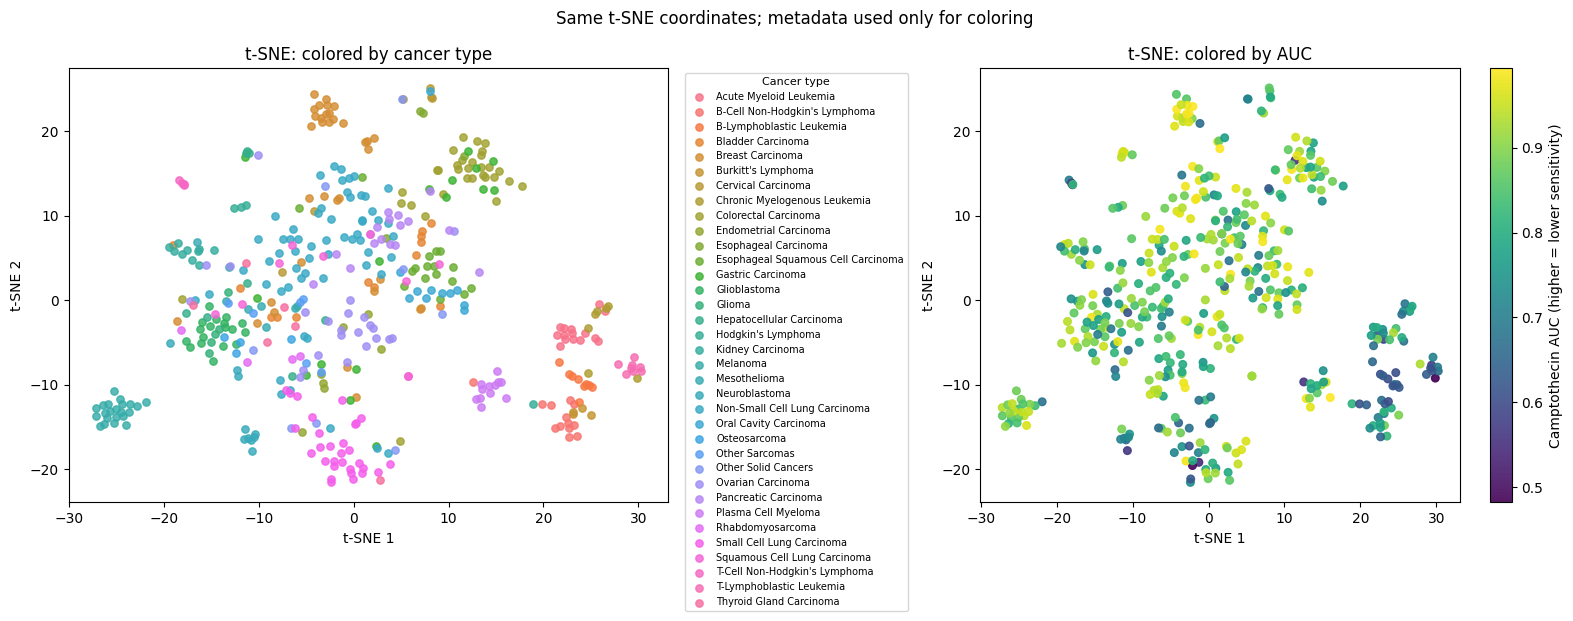

In [28]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Fixed settings for reproducibility
TSNE_SETTINGS = {
    "n_components": 2,
    "perplexity": 30,
    "learning_rate": "auto",
    "init": "pca",
    "metric": "euclidean",
    "random_state": 42
}

if TSNE_SETTINGS["perplexity"] >= len(pca_scores):
    raise ValueError("Perplexity must be smaller than the number of cell lines.")

# Fit t-SNE using expression-derived PCA scores only
tsne_model = TSNE(**TSNE_SETTINGS)
tsne_coordinates = tsne_model.fit_transform(pca_scores)

print("t-SNE input: first", pca_scores.shape[1], "PCA components")
print("t-SNE settings:")
for setting, value in TSNE_SETTINGS.items():
    print(f"{setting}: {value}")

# Use the same t-SNE coordinates in both plots
cancer_types = plot_metadata["cancer_type"].astype(str).to_numpy()
auc_values = plot_metadata["AUC"].to_numpy(dtype=float)
categories = sorted(np.unique(cancer_types))
colors = sns.color_palette("husl", n_colors=len(categories))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: color by cancer type
for cancer, color in zip(categories, colors):
    mask = cancer_types == cancer
    axes[0].scatter(
        tsne_coordinates[mask, 0],
        tsne_coordinates[mask, 1],
        color=color,
        label=cancer,
        s=28,
        alpha=0.82
    )

axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")
axes[0].set_title("t-SNE: colored by cancer type")
axes[0].legend(
    title="Cancer type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=7,
    title_fontsize=8
)

# Plot 2: color by continuous AUC
points = axes[1].scatter(
    tsne_coordinates[:, 0],
    tsne_coordinates[:, 1],
    c=auc_values,
    cmap="viridis",
    s=30,
    alpha=0.9
)

colorbar = fig.colorbar(points, ax=axes[1])
colorbar.set_label("Camptothecin AUC (higher = lower sensitivity)")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")
axes[1].set_title("t-SNE: colored by AUC")

fig.suptitle("Same t-SNE coordinates; metadata used only for coloring")
plt.tight_layout()
plt.show()

In [39]:
cluster_input = pca_scores[:, :50]
import plotly.express as px
from sklearn.cluster import KMeans

BEST_K = 3  # Replace 3 with the cluster count you choose from the table

# Fit the chosen K-means model using expression-derived PCA scores
final_model = KMeans(
    n_clusters=BEST_K,
    n_init=10,
    random_state=42
)
cluster_labels = final_model.fit_predict(cluster_input)

# Add the cluster labels to the UMAP coordinates and cell-line metadata
umap_plot = plot_metadata.reset_index(drop=True).copy()
umap_plot["UMAP1"] = umap_coordinates[:, 0]
umap_plot["UMAP2"] = umap_coordinates[:, 1]
umap_plot["cluster"] = [
    f"Cluster {label + 1}" for label in cluster_labels
]

# Interactive plot: hover over a dot to see its cell-line ID
fig = px.scatter(
    umap_plot,
    x="UMAP1",
    y="UMAP2",
    color="cluster",
    hover_name="sampleId",
    hover_data={
        "cancer_type": True,
        "AUC": ":.3f",
        "UMAP1": False,
        "UMAP2": False
    },
    title=f"UMAP colored by K-means clusters (k={BEST_K})"
)

fig.update_traces(marker={"size": 8, "opacity": 0.85})
fig.show()

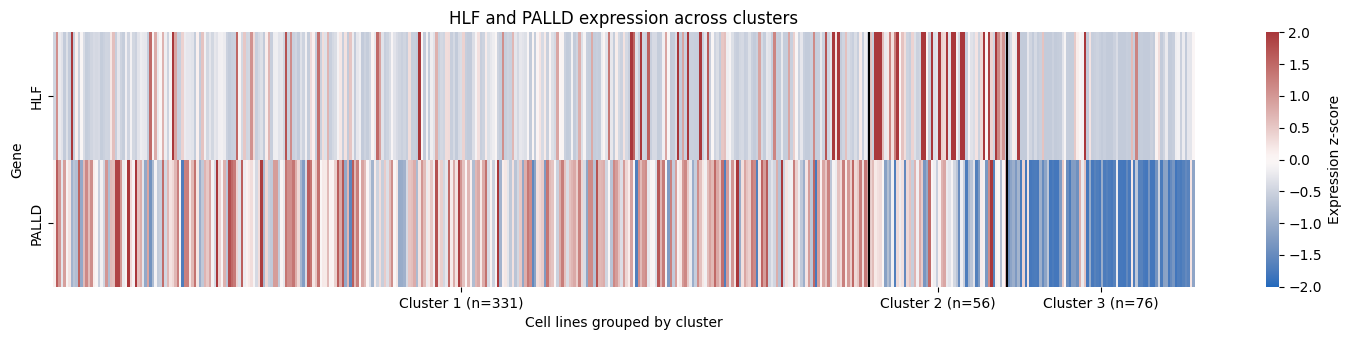

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

genes = ["HLF", "PALLD"]

# Check that both genes are present
missing = [gene for gene in genes if gene not in X_log.columns]
if missing:
    raise ValueError(f"Gene(s) not found in X_log: {missing}")

if len(cluster_labels) != len(X_log):
    raise ValueError("Cluster labels and expression rows do not match.")

# Match each cell line to its cluster
cluster = pd.Series(cluster_labels, index=X_log.index)

# Order cell lines by cluster
cluster_order = sorted(cluster.unique())
ordered_ids = [
    sample_id
    for cluster_id in cluster_order
    for sample_id in cluster.index[cluster == cluster_id]
]

# Arrange expression values: genes as rows, cell lines as columns
expression = X_log.loc[ordered_ids, genes].T

# Standardize each gene across cell lines for easier visual comparison
row_sd = expression.std(axis=1, ddof=0).replace(0, np.nan)
expression_z = (
    expression.sub(expression.mean(axis=1), axis=0)
    .div(row_sd, axis=0)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(15, 3.5))

sns.heatmap(
    expression_z,
    cmap="vlag",
    center=0,
    vmin=-2,
    vmax=2,
    xticklabels=False,
    yticklabels=True,
    cbar_kws={"label": "Expression z-score"},
    ax=ax
)

# Mark the boundaries between clusters
position = 0
tick_positions = []
tick_labels = []

for cluster_id in cluster_order:
    n_lines = int((cluster == cluster_id).sum())
    tick_positions.append(position + n_lines / 2)
    tick_labels.append(f"Cluster {cluster_id + 1} (n={n_lines})")

    if position > 0:
        ax.axvline(position, color="black", linewidth=1.5)

    position += n_lines

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=0)
ax.set_xlabel("Cell lines grouped by cluster")
ax.set_ylabel("Gene")
ax.set_title("HLF and PALLD expression across clusters")

plt.tight_layout()
plt.show()

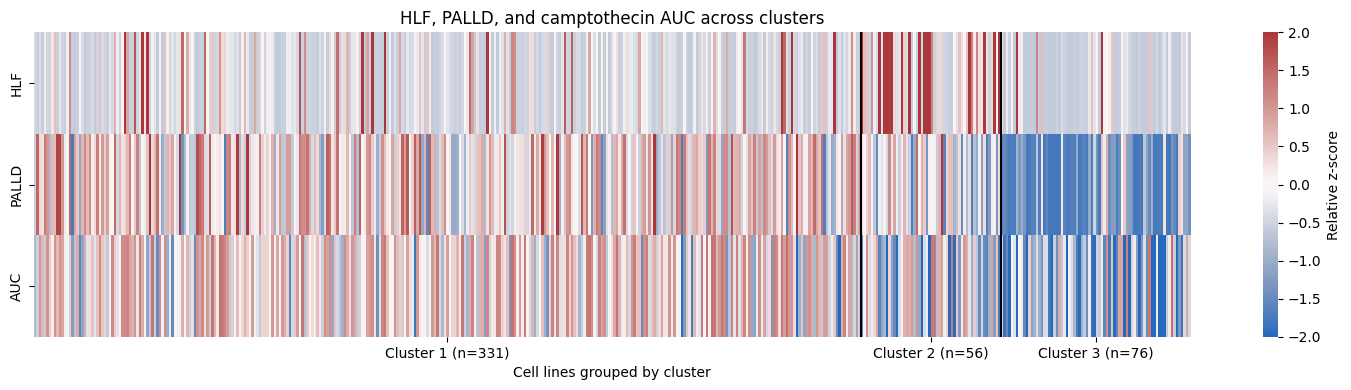

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Match metadata to expression rows
if "sampleId" in plot_metadata.columns:
    meta = plot_metadata.set_index("sampleId")
else:
    meta = plot_metadata.copy()

meta = meta.reindex(X_log.index)

# Build the plotting table
plot_data = pd.DataFrame(index=X_log.index)
plot_data["HLF"] = X_log["HLF"]
plot_data["PALLD"] = X_log["PALLD"]
plot_data["AUC"] = pd.to_numeric(meta["AUC"], errors="coerce")
plot_data["cluster"] = cluster_labels
plot_data = plot_data.dropna()

# Order cell lines by cluster
plot_data = plot_data.sort_values("cluster")

# Show relative values for each row: HLF, PALLD, and AUC
heatmap_data = plot_data[["HLF", "PALLD", "AUC"]].T
row_sd = heatmap_data.std(axis=1, ddof=0).replace(0, np.nan)
heatmap_z = (
    heatmap_data.sub(heatmap_data.mean(axis=1), axis=0)
    .div(row_sd, axis=0)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(15, 4))
sns.heatmap(
    heatmap_z,
    cmap="vlag",
    center=0,
    vmin=-2,
    vmax=2,
    xticklabels=False,
    yticklabels=True,
    cbar_kws={"label": "Relative z-score"},
    ax=ax
)

# Mark cluster boundaries and label each group
position = 0
tick_positions = []
tick_labels = []

for cluster_id, group in plot_data.groupby("cluster", sort=True):
    size = len(group)
    tick_positions.append(position + size / 2)
    tick_labels.append(f"Cluster {int(cluster_id) + 1} (n={size})")

    if position > 0:
        ax.axvline(position, color="black", linewidth=1.5)

    position += size

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=0)
ax.set_xlabel("Cell lines grouped by cluster")
ax.set_title("HLF, PALLD, and camptothecin AUC across clusters")
plt.tight_layout()
plt.show()

Explain:These use the same t-SNE coordinates, again colored by cancer type and AUC.
- Nearby dots represent cell lines with similar expression profiles in the t-SNE map.
- The two colors show whether those nearby lines also tend to share cancer types or AUC values.
Like UMAP, t-SNE axes do not have direct biological units. The map is exploratory; it does not measure prediction accuracy. **bold text**

In [33]:
import pandas as pd
import plotly.express as px
import statsmodels.formula.api as smf

GENE = "PALLD"  # Change this to RAD1, TOP1, or HLF

if GENE not in X_log.columns:
    raise ValueError(f"{GENE} was not found in X_log.")

# Align metadata with the expression rows by sampleId
if "sampleId" in plot_metadata.columns:
    meta = plot_metadata.set_index("sampleId")
else:
    meta = plot_metadata.copy()

meta = meta.reindex(X_log.index)

# Create one row per training cell line
df = pd.DataFrame(index=X_log.index)
df["sampleId"] = X_log.index.astype(str)
df["cancer_type"] = meta["cancer_type"].astype(str)
df["AUC"] = pd.to_numeric(meta["AUC"], errors="coerce")
df["gene_expression"] = pd.to_numeric(X_log[GENE], errors="coerce")
df = df.dropna()

# Standardize expression so the regression coefficient is per 1 SD
gene_sd = df["gene_expression"].std(ddof=0)
if gene_sd == 0:
    raise ValueError(f"{GENE} has no variation in these cell lines.")

df["gene_z"] = (
    df["gene_expression"] - df["gene_expression"].mean()
) / gene_sd

# Fit regression adjusted for cancer type
model = smf.ols(
    "AUC ~ gene_z + C(cancer_type)",
    data=df
).fit(cov_type="HC3")

beta = model.params["gene_z"]
ci_low, ci_high = model.conf_int().loc["gene_z"]
p_value = model.pvalues["gene_z"]

print(f"Gene: {GENE}")
print(f"Training cell lines: {len(df)}")
print(f"Adjusted coefficient per 1 SD increase: {beta:.4f}")
print(f"95% confidence interval: ({ci_low:.4f}, {ci_high:.4f})")
print(f"P-value: {p_value:.4g}")

# Center expression and AUC within each cancer type for the adjusted plot
df["expression_adjusted"] = (
    df["gene_z"]
    - df.groupby("cancer_type")["gene_z"].transform("mean")
)
df["AUC_adjusted"] = (
    df["AUC"]
    - df.groupby("cancer_type")["AUC"].transform("mean")
)

# Make an interactive scatter plot
fig = px.scatter(
    df,
    x="expression_adjusted",
    y="AUC_adjusted",
    color="cancer_type",
    hover_name="sampleId",
    hover_data={
        "gene_expression": ":.3f",
        "AUC": ":.3f",
        "cancer_type": True,
        "expression_adjusted": False,
        "AUC_adjusted": False
    },
    title=f"{GENE} expression and camptothecin AUC, adjusted for cancer type"
)

# Add the cancer-type-adjusted regression line
x_line = [
    df["expression_adjusted"].min(),
    df["expression_adjusted"].max()
]
fig.add_scatter(
    x=x_line,
    y=[beta * x for x in x_line],
    mode="lines",
    name="Adjusted regression line",
    line={"color": "black", "width": 3}
)

fig.update_layout(
    xaxis_title=f"{GENE} expression centered within cancer type (SD units)",
    yaxis_title="Camptothecin AUC centered within cancer type"
)
fig.show()

Gene: PALLD
Training cell lines: 463
Adjusted coefficient per 1 SD increase: 0.0055
95% confidence interval: (-0.0079, 0.0188)
P-value: 0.4233
